> **Antecedente de la versión 1.** El alcance vigente desde el 24/11/2026 es manzana roja, banano y limón. Este cuaderno conserva la preparación anterior con naranjas para trazabilidad. Continuar en el cuaderno 04 y consultar `config/alcance_actual.json`.

# Revisión inicial de imágenes y etiquetas de calidad

**Proyecto estado de frutas · Algoritmos y Programación III**

Trabajamos con **manzana roja, banano y naranja**. Este primer cuaderno desarrolla
la comprensión y revisión de los datos de CRISP-DM: descarga o localiza las imágenes,
comprueba su integridad, muestra ejemplos y permite revisar sus etiquetas.

Conservamos las categorías originales **buena** y **mala**. Proponemos una tercera
categoría, **intermedia**, para defectos superficiales y localizados. La etiqueta
original y la revisada se guardan en columnas diferentes. Una propuesta del asistente
o una imagen de la carpeta mixta no se convierten automáticamente en una etiqueta confirmada.

El código obtiene tablas, imágenes y controles; las explicaciones e interpretaciones
están en Markdown. No entrenamos modelos en esta etapa.

## 1. Entorno y rutas

Ejecutar de arriba abajo desde `notebooks/`, la raíz del proyecto o `APOIII/`.
Usar Python 3.11 o superior e instalar `requirements.txt` en el entorno del kernel.
Para esta revisión se necesitan principalmente `kagglehub`, `pandas`, `numpy`,
`Pillow`, `matplotlib`, `ipywidgets` e `ipykernel`.

Si faltan las dependencias de revisión, ejecutar en una celda:
`%pip install kagglehub pandas numpy pillow matplotlib ipywidgets ipykernel`
y reiniciar el kernel. No es necesario instalar un framework de redes neuronales
para revisar estas imágenes.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import html
import io
import json
import os
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, clear_output

SEMILLA = 42
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
CALIDADES = ['buena', 'intermedia', 'mala']

candidatas = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / 'proyecto_estado_frutas']
PROYECTO = next((p for p in candidatas
                 if (p / 'requirements.txt').is_file()
                 and (p / 'estructura_proyecto.md').is_file()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde proyecto_estado_frutas o APOIII.')

RUTA_LOCAL = PROYECTO / 'data/raw/fruit-quality-classification'
SALIDAS = PROYECTO / 'experiments/results/revision_datos'
ANOTACIONES = PROYECTO / 'data/annotations'
SALIDAS.mkdir(parents=True, exist_ok=True)
ANOTACIONES.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Proyecto:', PROYECTO)

Proyecto: C:\Users\felipe\APOIII\proyecto_estado_frutas


## 2. Imágenes públicas

Fuente: [Fruit Quality Classification, ryandpark, Kaggle](https://www.kaggle.com/datasets/ryandpark/fruit-quality-classification).
Las carpetas descargadas para esta revisión corresponden a la **versión 1**.
Se conservaron los archivos originales y se registró su procedencia en
`procedencia_descarga.json` dentro de la carpeta de datos.

Ya se descargaron únicamente las nueve carpetas de nuestras tres frutas: buena,
mala y mixta. El archivo completo de Kaggle contiene otras frutas y ocupa unos
3,25 GB comprimidos. La celda utiliza primero los datos locales. Si no existen,
usa la descarga completa indicada por el equipo, con una comprobación previa de
espacio para descarga y extracción. También se puede cambiar `RUTA_LOCAL` por una
carpeta donde ya se tenga el conjunto descargado.

In [2]:
if RUTA_LOCAL.is_dir() and any(
        p.suffix.lower() in EXTENSIONES for p in RUTA_LOCAL.rglob('*') if p.is_file()):
    ruta_dataset = RUTA_LOCAL
    print('Se utilizan las imágenes locales; no se vuelve a descargar el conjunto.')
else:
    cache = PROYECTO / 'data/external/kagglehub'
    cache.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(cache).free < 10 * 1024**3:
        raise OSError('Se requieren al menos 10 GiB libres para descargar y extraer '
                      'el conjunto completo. Usa RUTA_LOCAL con los datos disponibles.')
    os.environ['KAGGLEHUB_CACHE'] = str(cache)
    import kagglehub
    path = kagglehub.dataset_download('ryandpark/fruit-quality-classification')
    ruta_dataset = Path(path)

print('Ruta de imágenes:', ruta_dataset)
archivo_procedencia = ruta_dataset / 'procedencia_descarga.json'
if archivo_procedencia.is_file():
    procedencia = json.loads(archivo_procedencia.read_text(encoding='utf-8'))
    print('Versión:', procedencia['version'], '| Alcance:', procedencia['scope'])

Se utilizan las imágenes locales; no se vuelve a descargar el conjunto.
Ruta de imágenes: C:\Users\felipe\APOIII\proyecto_estado_frutas\data\raw\fruit-quality-classification
Versión: 1 | Alcance: Nueve carpetas de manzana, banano y naranja: buena, mala y mixed quality. Otras frutas no descargadas.


## 3. Inventario e integridad

Reconocemos las carpetas reales sin inferir calidad a partir del color. La carpeta
`Mixed Qualit_Fruits` se conserva como **sin etiqueta**: mezcla de calidad no
significa calidad intermedia. Además, puede contener varias frutas en una fotografía.

Leemos completamente cada archivo para detectar imágenes ilegibles, registramos sus
dimensiones y calculamos SHA-256 para detectar archivos exactamente iguales.
La huella no detecta todas las versiones recortadas, rotadas o recomprimidas.
Los originales se conservan y los errores se reportan.

In [3]:
CARPETAS = {
    ('Bad Quality_Fruits', 'Apple_Bad'): ('manzana', 'mala'),
    ('Bad Quality_Fruits', 'Banana_Bad'): ('banano', 'mala'),
    ('Bad Quality_Fruits', 'Orange_Bad'): ('naranja', 'mala'),
    ('Good Quality_Fruits', 'Apple_Good'): ('manzana', 'buena'),
    ('Good Quality_Fruits', 'Banana_Good'): ('banano', 'buena'),
    ('Good Quality_Fruits', 'Orange_Good'): ('naranja', 'buena'),
    ('Mixed Qualit_Fruits', 'Apple'): ('manzana', 'sin_etiqueta'),
    ('Mixed Qualit_Fruits', 'Banana'): ('banano', 'sin_etiqueta'),
    ('Mixed Qualit_Fruits', 'Orange'): ('naranja', 'sin_etiqueta'),
}

registros = []
for archivo in sorted(ruta_dataset.rglob('*')):
    if not archivo.is_file() or archivo.suffix.lower() not in EXTENSIONES:
        continue
    relativa = archivo.relative_to(ruta_dataset)
    coincidencias = [datos for carpeta, datos in CARPETAS.items()
                     if '/'.join(carpeta) == relativa.parent.as_posix()]
    if not coincidencias:
        continue
    fruta, calidad = coincidencias[0]
    fila = {'id_imagen': hashlib.sha256(relativa.as_posix().encode()).hexdigest()[:16],
            'ruta_relativa': relativa.as_posix(), 'fruta': fruta,
            'calidad_original': calidad, 'archivo_legible': False,
            'ancho': None, 'alto': None, 'bytes': archivo.stat().st_size,
            'sha256': '', 'error_lectura': ''}
    try:
        contenido = archivo.read_bytes()
        fila['sha256'] = hashlib.sha256(contenido).hexdigest()
        with Image.open(io.BytesIO(contenido)) as imagen:
            imagen.load()
            imagen = ImageOps.exif_transpose(imagen)
            fila.update(archivo_legible=True, ancho=imagen.width, alto=imagen.height)
    except (OSError, ValueError, Image.DecompressionBombError) as error:
        fila['error_lectura'] = f'{type(error).__name__}: {error}'
    registros.append(fila)

inventario = pd.DataFrame(registros)
if inventario.empty:
    raise ValueError('No se encontraron las carpetas esperadas. Revisar RUTA_LOCAL.')
assert inventario['id_imagen'].is_unique
inventario[['ancho', 'alto']] = inventario[['ancho', 'alto']].astype('Int64')
inventario['duplicado_exacto'] = (inventario['sha256'].ne('') &
                                 inventario['sha256'].duplicated(keep=False))
inventario['grupo_duplicado'] = inventario['sha256']
inventario.to_csv(SALIDAS / 'inventario_imagenes.csv', index=False, encoding='utf-8-sig')
print('Imágenes inventariadas:', len(inventario))
print('Memoria del inventario (MB):', round(inventario.memory_usage(deep=True).sum() / 1e6, 2))

Imágenes inventariadas: 7388
Memoria del inventario (MB): 4.69


,fruta,calidad_original,imagenes,legibles,archivos_en_grupos_duplicados
0,banano,buena,1113,1113,0
1,banano,mala,1087,1087,0
2,banano,sin_etiqueta,285,285,0
3,manzana,buena,1149,1149,0
4,manzana,mala,1141,1141,0
5,manzana,sin_etiqueta,113,113,0
6,naranja,buena,1216,1216,0
7,naranja,mala,1159,1159,0
8,naranja,sin_etiqueta,125,125,0


,ancho,alto
count,7388.0,7388.0
mean,237.4,252.7
std,29.1,14.1
min,144.0,192.0
25%,192.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


Archivos ilegibles: 0
Archivos adicionales por duplicación exacta: 0


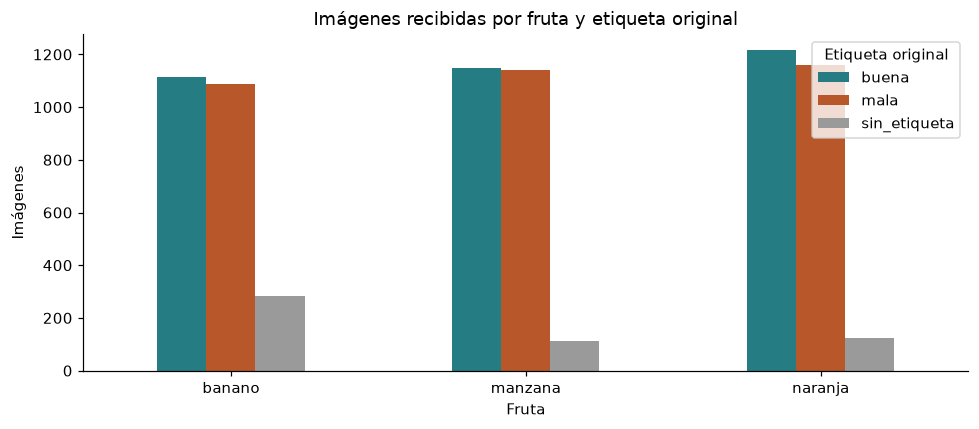

In [4]:
resumen = (inventario.groupby(['fruta', 'calidad_original'], observed=True)
           .agg(imagenes=('id_imagen', 'size'), legibles=('archivo_legible', 'sum'),
                archivos_en_grupos_duplicados=('duplicado_exacto', 'sum'))
           .reset_index())
display(resumen)
display(inventario.loc[inventario['archivo_legible'], ['ancho', 'alto']].describe().round(1))
errores = inventario.loc[~inventario['archivo_legible']]
duplicados = inventario.loc[inventario['duplicado_exacto']]
errores.to_csv(SALIDAS / 'errores_lectura.csv', index=False, encoding='utf-8-sig')
duplicados.to_csv(SALIDAS / 'duplicados_exactos.csv', index=False, encoding='utf-8-sig')
resumen.to_csv(SALIDAS / 'resumen_por_fruta.csv', index=False, encoding='utf-8-sig')
print('Archivos ilegibles:', len(errores))
print('Archivos adicionales por duplicación exacta:',
      inventario.loc[inventario['sha256'].ne(''), 'sha256'].duplicated().sum())

tabla = pd.crosstab(inventario['fruta'], inventario['calidad_original'])
tabla.plot.bar(figsize=(9, 4), rot=0,
               color={'buena': '#267c83', 'mala': '#b7572a', 'sin_etiqueta': '#9a9a9a'})
plt.title('Imágenes recibidas por fruta y etiqueta original')
plt.xlabel('Fruta')
plt.ylabel('Imágenes')
plt.legend(title='Etiqueta original')
plt.tight_layout()
plt.show()

### Interpretación de los datos recibidos

El conjunto local contiene **7.388 imágenes**: 6.865 en buena/mala calidad y 523
en las carpetas mixtas de las tres frutas. Son cantidades recibidas, **no cantidades
listas para entrenar**. En particular, `Apple_Good` incluye manzanas verdes y amarillas,
y hay fotografías de racimos y de varias frutas incluso fuera de la carpeta mixta.

La muestra visual también presenta manos, guantes y fondos variados. Esas condiciones
deben revisarse para que el futuro modelo no dependa del fondo o de la forma de sujetar
la fruta. Los resultados de integridad y duplicados se calculan en las tablas anteriores.

## 4. Muestra visual reproducible

Mostramos ocho ejemplos por fruta y etiqueta original, con la misma semilla.
Esta muestra sirve para entender los datos; no es una evaluación de un modelo.
Los identificadores permiten volver a encontrar cada imagen en el inventario.

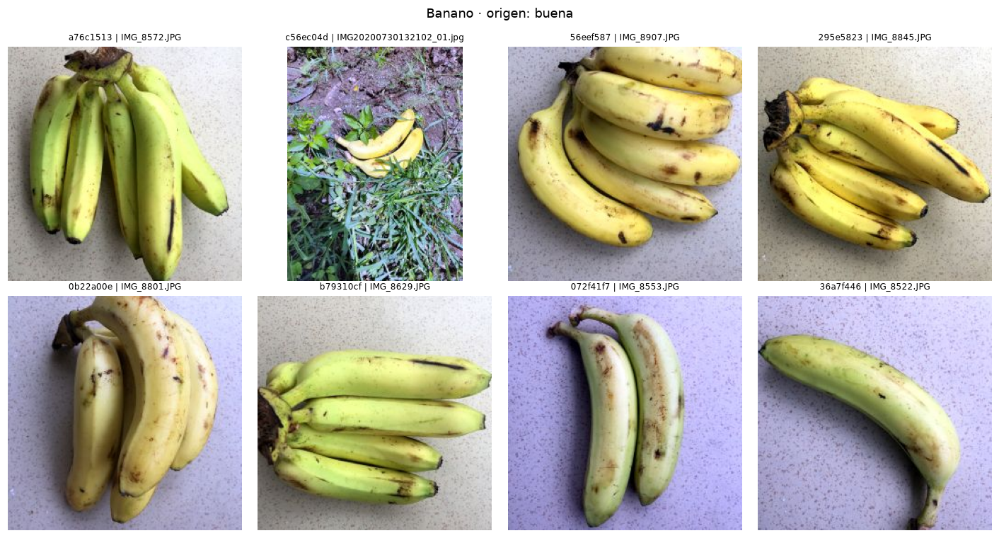

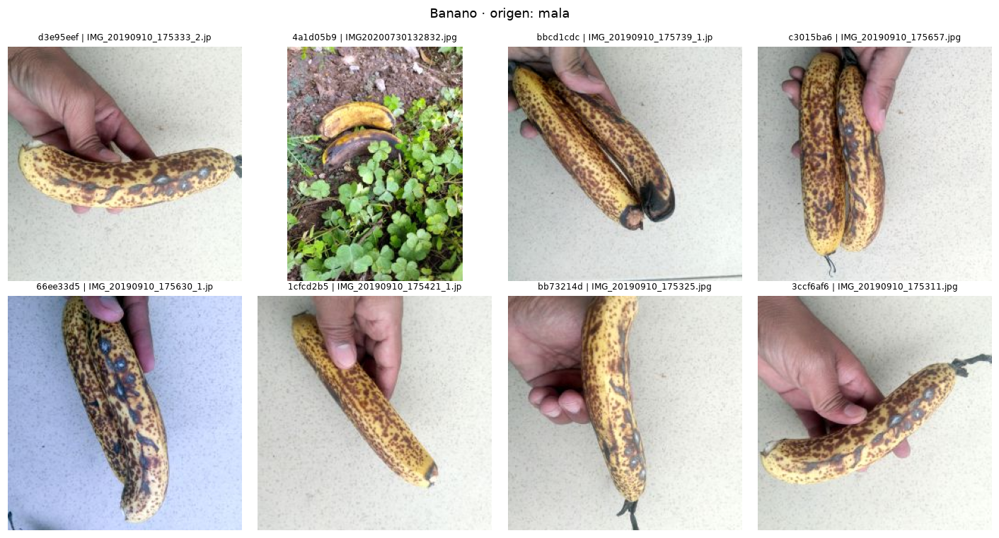

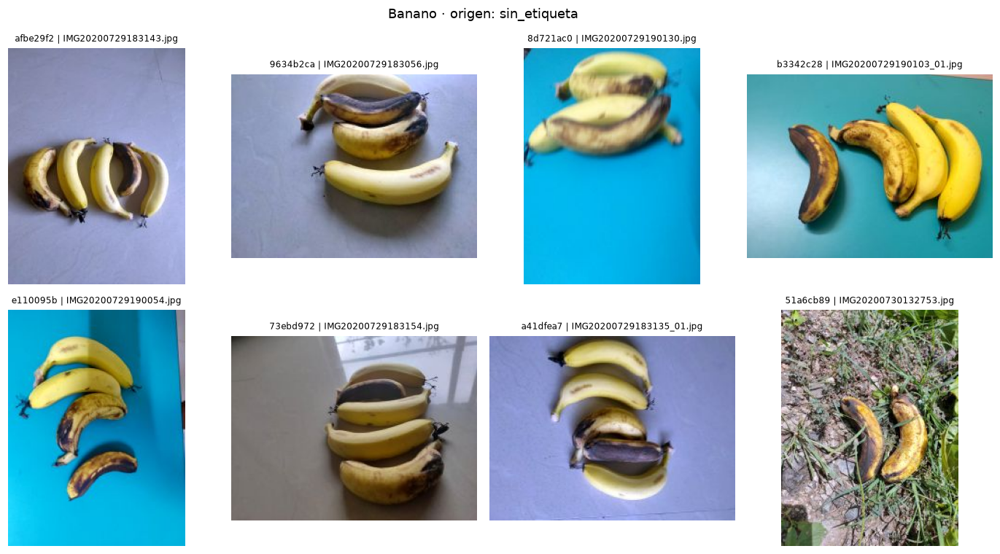

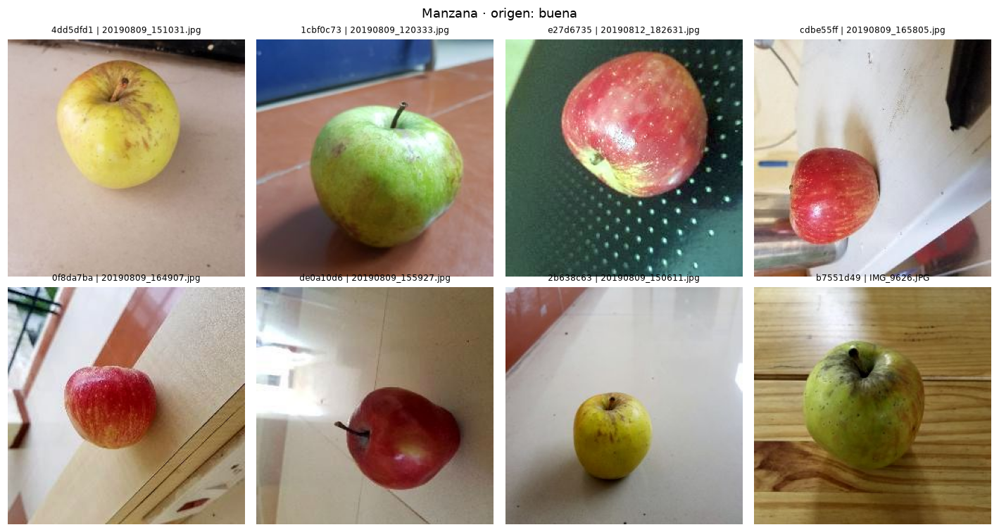

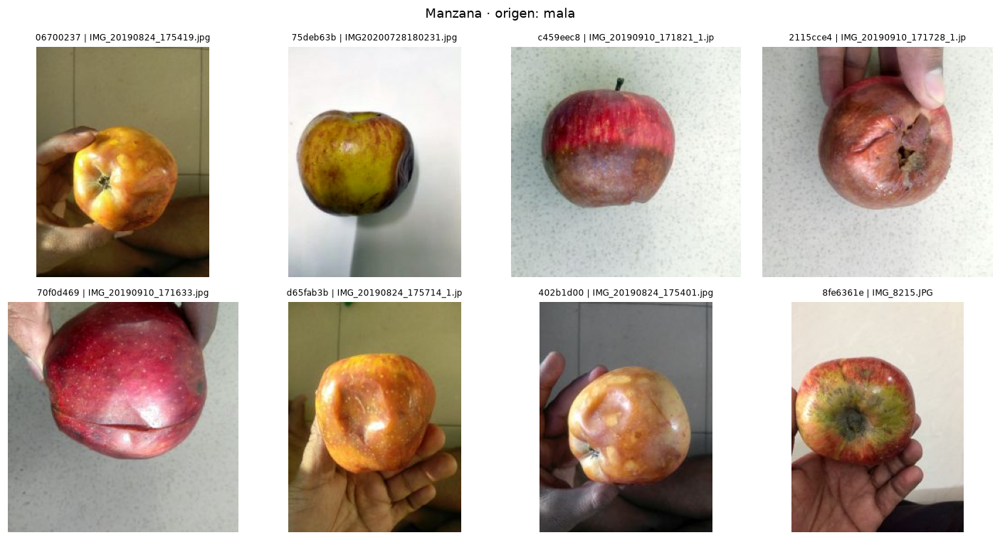

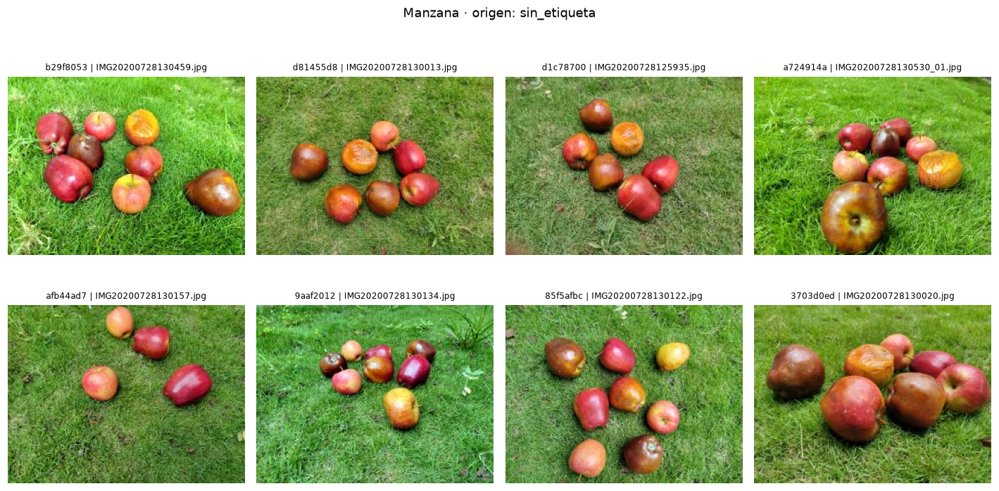

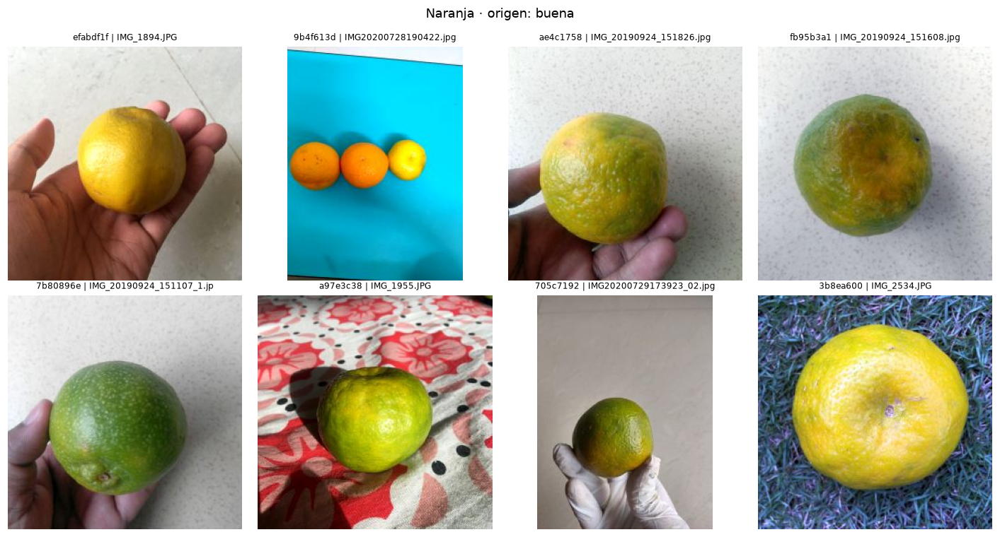

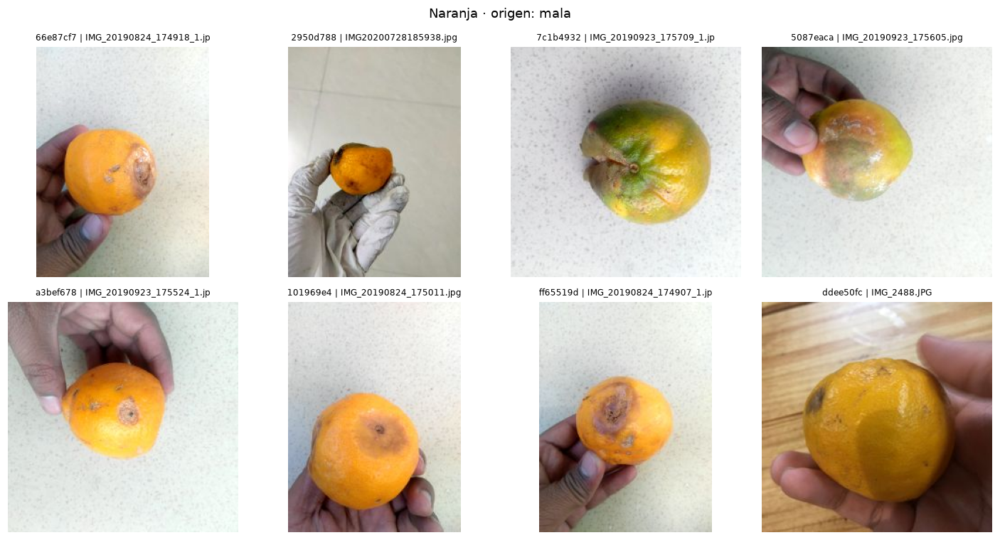

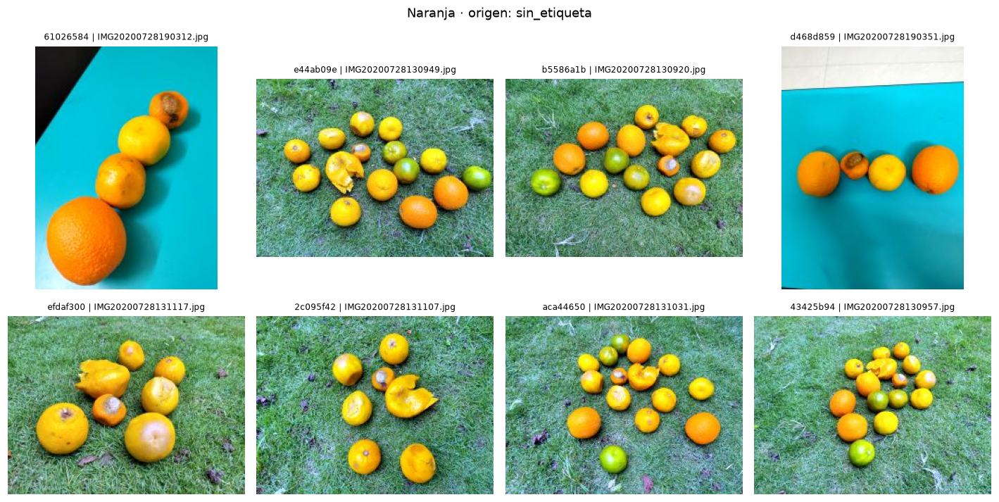

In [5]:
validas = inventario.loc[inventario['archivo_legible']].copy()
ids_muestra = []
for _, grupo in validas.groupby(['fruta', 'calidad_original'], sort=True):
    # El orden de ruta y la semilla hacen reproducible la selección.
    ids = grupo.sort_values('ruta_relativa')['id_imagen'].tolist()
    ids_muestra.extend(random.Random(SEMILLA).sample(ids, min(8, len(ids))))
muestra = validas.set_index('id_imagen').loc[ids_muestra].reset_index()
muestra.to_csv(SALIDAS / 'muestra_visual.csv', index=False, encoding='utf-8-sig')

def mostrar_galeria(filas, titulo):
    fig, ejes = plt.subplots(2, 4, figsize=(13, 7))
    for eje in ejes.flat:
        eje.axis('off')
    for eje, fila in zip(ejes.flat, filas.itertuples()):
        with Image.open(ruta_dataset / fila.ruta_relativa) as imagen:
            imagen = ImageOps.exif_transpose(imagen).convert('RGB')
            eje.imshow(imagen)
        eje.set_title(f'{fila.id_imagen[:8]} | {Path(fila.ruta_relativa).name[:24]}', fontsize=8)
    fig.suptitle(titulo)
    fig.tight_layout()
    return fig

for (fruta, calidad), grupo in muestra.groupby(['fruta', 'calidad_original'], sort=True):
    figura = mostrar_galeria(grupo, f'{fruta.capitalize()} · origen: {calidad}')
    figura.savefig(SALIDAS / f'galeria_{fruta}_{calidad}.jpg', dpi=110)
    plt.show()

## 5. Criterios para la clasificación revisada

Estas son **reglas iniciales del equipo**, pendientes de calibrar con ejemplos:

| Calidad | Evidencia visual |
|---|---|
| **Buena** | Superficie visible íntegra, sin lesiones importantes. Admite marcas naturales y cambios normales de color. |
| **Intermedia** | Rozaduras, cicatrices o lesiones superficiales localizadas, con el resto de la superficie conservada y sin signos claros de deterioro severo. |
| **Mala** | Deterioro extenso, lesiones profundas, grietas con tejido expuesto o signos visibles compatibles con moho o podredumbre. |

Una lesión severa tiene prioridad aunque ocupe una parte pequeña de la imagen.
No fijamos porcentajes arbitrarios de píxeles dañados sin haber anotado o segmentado
los defectos. Tampoco llamamos intermedio a todo caso difícil de decidir.

- **Manzana:** incluir solamente ejemplares rojos o predominantemente rojos; si el
  deterioro impide determinarlo, dejar pendiente. No se puede identificar la variedad
  con certeza en todas las fotografías.
- **Banano:** los puntos cafés de maduración por sí solos no implican mala calidad.
  Revisar el tipo y extensión de las lesiones.
- **Naranja:** el verde de la cáscara por sí solo no implica mala calidad.
- **Varias frutas:** marcar para segmentación; no asignar una sola calidad a ejemplares distintos.
- **Imagen ambigua o desenfocada:** mantener pendiente o excluir justificadamente.

Solo evaluamos lo visible en la fotografía; no certificamos el estado interno de la fruta.

Referencias para construir los criterios: [UC Davis, manzana](https://postharvest.ucdavis.edu/produce-facts-sheets/apple-golden-delicious),
[UC Davis, banano](https://postharvest.ucdavis.edu/produce-facts-sheets/banana),
[UC Davis, naranja](https://postharvest.ucdavis.edu/ar/produce-facts-sheets/orange),
[Iowa State, maduración del banano](https://spendsmart.extension.iastate.edu/produce-item/bananas/).

## 6. Propuestas iniciales y registro de revisión

`propuestas_revision_inicial.csv` contiene una revisión visual preliminar del asistente
sobre una muestra. Sus propuestas iniciales pueden cambiar. Las revisiones posteriores del asistente están atribuidas explícitamente a ese revisor y pueden ser corregidas por el equipo.
Los campos vacíos significan que no se puede decidir con suficiente claridad.

La revisión del equipo se guarda en otro archivo, `revision_equipo.csv`, y nunca
reescribe las etiquetas del conjunto original. Volver a ejecutar el cuaderno conserva
las revisiones guardadas. La huella permite advertir si cambió el archivo revisado.

Propuestas visuales disponibles: 50
Revisiones guardadas (consultar revisor): 194


,id_imagen,fruta,calidad_original,calidad_propuesta,comentario_propuesta
281,2e32661c1e9c56f3,manzana,mala,intermedia,Rozaduras y una zona parda localizada en la pa...
357,810428c750ecb8cb,manzana,mala,intermedia,Zona oscura localizada sin rotura visible; can...
2513,101969e4e1776f11,naranja,mala,intermedia,Zona parda localizada sin rotura profunda evid...
2685,a3bef67825e11ad0,naranja,mala,intermedia,Lesión circular localizada con resto de superf...
3344,ddee50fcb7d7a0be,naranja,mala,intermedia,Marca oscura localizada y superficie restante ...
6765,3b8ea60075fa8693,naranja,buena,intermedia,Varias marcas pequeñas y localizadas sobre una...


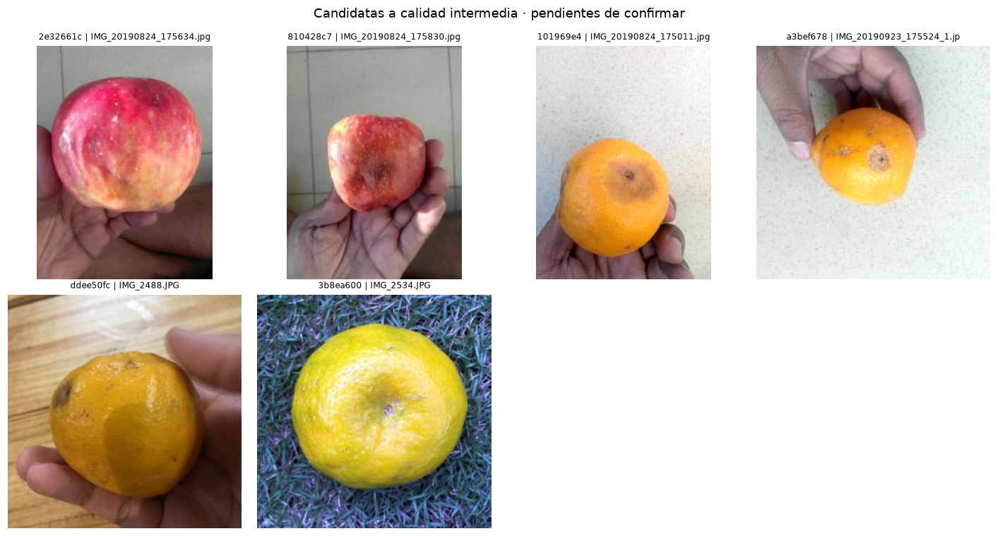

In [6]:
ARCHIVO_PROPUESTAS = ANOTACIONES / 'propuestas_revision_inicial.csv'
ARCHIVO_REVISION = ANOTACIONES / 'revision_equipo.csv'
COLUMNAS_REVISION = ['id_imagen', 'sha256', 'calidad_revisada', 'decision',
                     'manzana_roja', 'ejemplar_individual', 'grupo_ejemplar',
                     'observaciones', 'revisor', 'fecha_revision_utc']

if ARCHIVO_PROPUESTAS.is_file():
    propuestas = pd.read_csv(ARCHIVO_PROPUESTAS, dtype=str, keep_default_na=False)
    assert propuestas['ruta_relativa'].is_unique
else:
    propuestas = pd.DataFrame(columns=['ruta_relativa', 'calidad_propuesta',
        'manzana_roja_propuesta', 'individual_propuesto', 'decision_propuesta',
        'comentario_propuesta'])

base_revision = validas.merge(propuestas, on='ruta_relativa', how='left', validate='one_to_one')
columnas_propuesta = [c for c in propuestas if c != 'ruta_relativa']
base_revision[columnas_propuesta] = base_revision[columnas_propuesta].fillna('')

def leer_revisiones():
    if not ARCHIVO_REVISION.is_file():
        return pd.DataFrame(columns=COLUMNAS_REVISION)
    revisiones = pd.read_csv(ARCHIVO_REVISION, dtype=str, keep_default_na=False)
    if not revisiones['id_imagen'].is_unique:
        raise ValueError('Hay revisiones repetidas para un identificador; revisar el CSV.')
    return revisiones[COLUMNAS_REVISION]

def guardar_revision(id_imagen, calidad, decision, manzana_roja, individual,
                     observaciones, revisor, grupo_ejemplar=''):
    fila = validas.set_index('id_imagen').loc[id_imagen]
    if decision not in {'incluir', 'excluir', 'pendiente', 'segmentar'}:
        raise ValueError('Decisión no válida.')
    if manzana_roja not in {'si', 'no', 'pendiente', 'no_aplica'} or individual not in {'si', 'no', 'pendiente'}:
        raise ValueError('Respuesta de alcance no válida.')
    if not revisor.strip():
        raise ValueError('Indicar quién realiza la revisión.')
    if decision == 'incluir':
        if calidad not in CALIDADES or individual != 'si':
            raise ValueError('Para incluir se necesita calidad y un solo ejemplar.')
        if fila['fruta'] == 'manzana' and manzana_roja != 'si':
            raise ValueError('Para incluir una manzana hay que confirmar que es roja.')
    if decision == 'segmentar' and individual != 'no':
        raise ValueError('La segmentación se reserva para fotografías con varios ejemplares.')
    if (decision in {'excluir', 'segmentar'} or calidad == 'intermedia') and not observaciones.strip():
        raise ValueError('Explicar la exclusión, segmentación o elección de intermedia.')
    actual = hashlib.sha256((ruta_dataset / fila['ruta_relativa']).read_bytes()).hexdigest()
    if actual != fila['sha256']:
        raise ValueError('La imagen cambió; volver a ejecutar el inventario antes de revisarla.')
    nueva = dict(zip(COLUMNAS_REVISION, [id_imagen, actual, calidad, decision,
        manzana_roja if fila['fruta'] == 'manzana' else 'no_aplica', individual,
        grupo_ejemplar.strip(), observaciones.strip(), revisor.strip(),
        datetime.now(timezone.utc).isoformat()]))
    revisiones = leer_revisiones()
    revisiones = revisiones.loc[revisiones['id_imagen'].ne(id_imagen)]
    revisiones = pd.concat([revisiones, pd.DataFrame([nueva])], ignore_index=True)
    temporal = ARCHIVO_REVISION.with_suffix('.tmp')
    revisiones.to_csv(temporal, index=False, encoding='utf-8-sig')
    temporal.replace(ARCHIVO_REVISION)
    return nueva

print('Propuestas visuales disponibles:', len(propuestas))
print('Revisiones guardadas (consultar revisor):', len(leer_revisiones()))
display(base_revision.loc[base_revision['calidad_propuesta'].eq('intermedia'),
    ['id_imagen', 'fruta', 'calidad_original', 'calidad_propuesta', 'comentario_propuesta']])
candidatas_intermedias = base_revision.loc[base_revision['calidad_propuesta'].eq('intermedia')]
if not candidatas_intermedias.empty:
    figura = mostrar_galeria(candidatas_intermedias.head(8),
                            'Candidatas a calidad intermedia · pendientes de confirmar')
    figura.savefig(SALIDAS / 'candidatas_intermedias.jpg', dpi=110)
    plt.show()

## 7. Revisor visual

1. Empezar por la **muestra con propuestas**; luego cambiar a **todas las imágenes**.
2. Mirar la fotografía y comprobar manzana roja y ejemplar individual.
3. Elegir calidad y decisión. Las propuestas aparecen como referencia; el formulario
   de una imagen nueva comienza sin decisiones confirmadas.
4. Escribir la evidencia si se elige intermedia y el motivo si se excluye o segmenta.
5. Pulsar **Guardar revisión**. Se puede volver a la imagen y corregirla.

`Grupo del ejemplar` permite identificar fotos del mismo fruto: asignar el mismo valor
a todas sus vistas para mantenerlas juntas en una futura partición. Si se desconoce,
dejarlo vacío; la huella de duplicación no identifica por sí sola al fruto físico.
El revisor trabaja de forma local para una persona a la vez.

In [7]:
import ipywidgets as widgets

filtro_fruta = widgets.Dropdown(options=['todas', 'manzana', 'banano', 'naranja'], description='Fruta:')
filtro_origen = widgets.Dropdown(options=['todas', 'buena', 'mala', 'sin_etiqueta'], description='Origen:')
modo = widgets.Dropdown(options=['muestra con propuestas', 'todas las imágenes'], description='Revisar:')
selector = widgets.Dropdown(description='Imagen:', layout=widgets.Layout(width='95%'))
vista, mensaje = widgets.Output(), widgets.Output()
calidad_widget = widgets.Dropdown(options=[('Sin decidir', ''), ('Buena', 'buena'),
    ('Intermedia', 'intermedia'), ('Mala', 'mala')], description='Calidad:')
decision_widget = widgets.Dropdown(options=['pendiente', 'incluir', 'excluir', 'segmentar'], description='Decisión:')
roja_widget = widgets.Dropdown(options=['pendiente', 'si', 'no', 'no_aplica'], description='¿Roja?:')
individual_widget = widgets.Dropdown(options=['pendiente', 'si', 'no'], description='¿Una fruta?:')
grupo_widget = widgets.Text(description='Grupo fruto:', placeholder='Mismo código para vistas del mismo ejemplar')
notas_widget = widgets.Textarea(description='Evidencia:', layout=widgets.Layout(width='95%', height='85px'))
revisor_widget = widgets.Text(value='Equipo', description='Revisor:')
guardar_boton = widgets.Button(description='Guardar revisión', button_style='success')
anterior_boton = widgets.Button(description='Anterior')
siguiente_boton = widgets.Button(description='Siguiente')

def mostrar_imagen(change=None):
    with vista:
        clear_output(wait=True)
        if not selector.value:
            print('No hay imágenes con estos filtros.')
            return
        fila = base_revision.set_index('id_imagen').loc[selector.value]
        print(f"{fila['fruta']} | Origen: {fila['calidad_original']} | ID: {fila.name}")
        print('Archivo:', fila['ruta_relativa'])
        print('Propuesta visual:', fila['calidad_propuesta'] or 'sin decidir',
              '|', fila['comentario_propuesta'])
        print('Alcance propuesto:', fila['decision_propuesta'] or 'pendiente',
              '| Roja:', fila['manzana_roja_propuesta'], '| Individual:', fila['individual_propuesto'])
        with Image.open(ruta_dataset / fila['ruta_relativa']) as imagen:
            imagen = ImageOps.exif_transpose(imagen).convert('RGB')
            imagen.thumbnail((650, 500))
            display(imagen)
        guardadas = leer_revisiones().set_index('id_imagen')
        previa = guardadas.loc[fila.name].to_dict() if fila.name in guardadas.index else {}
        if previa and previa['sha256'] != fila['sha256']:
            print('La revisión guardada corresponde a otro contenido; revisar de nuevo.')
            previa = {}
        calidad_widget.value = previa.get('calidad_revisada', '')
        decision_widget.value = previa.get('decision', 'pendiente')
        roja_widget.disabled = fila['fruta'] != 'manzana'
        roja_widget.value = previa.get('manzana_roja', 'pendiente' if fila['fruta'] == 'manzana' else 'no_aplica')
        individual_widget.value = previa.get('ejemplar_individual', 'pendiente')
        grupo_widget.value = previa.get('grupo_ejemplar', '')
        notas_widget.value = previa.get('observaciones', '')

def filtrar_imagenes(change=None):
    filas = base_revision
    if modo.value == 'muestra con propuestas':
        filas = filas.loc[filas['ruta_relativa'].isin(propuestas['ruta_relativa'])]
    if filtro_fruta.value != 'todas':
        filas = filas.loc[filas['fruta'].eq(filtro_fruta.value)]
    if filtro_origen.value != 'todas':
        filas = filas.loc[filas['calidad_original'].eq(filtro_origen.value)]
    opciones = [(f'{i+1}/{len(filas)} | {f.fruta} | {f.calidad_original} | {Path(f.ruta_relativa).name}',
                 f.id_imagen) for i, f in enumerate(filas.itertuples())]
    selector.options = opciones
    selector.value = opciones[0][1] if opciones else None
    mostrar_imagen()

def mover_imagen(paso):
    ids = [valor for _, valor in selector.options]
    if selector.value in ids:
        selector.value = ids[max(0, min(len(ids)-1, ids.index(selector.value) + paso))]

def guardar_desde_formulario(button):
    with mensaje:
        clear_output(wait=True)
        try:
            if not selector.value:
                raise ValueError('Seleccionar una imagen.')
            guardar_revision(selector.value, calidad_widget.value, decision_widget.value,
                roja_widget.value, individual_widget.value, notas_widget.value,
                revisor_widget.value, grupo_widget.value)
            print('Revisión guardada. Puedes continuar con Siguiente.')
        except (ValueError, OSError) as error:
            print(error)

for control in [modo, filtro_fruta, filtro_origen]:
    control.observe(filtrar_imagenes, names='value')
selector.observe(mostrar_imagen, names='value')
guardar_boton.on_click(guardar_desde_formulario)
anterior_boton.on_click(lambda button: mover_imagen(-1))
siguiente_boton.on_click(lambda button: mover_imagen(1))
display(widgets.VBox([modo, widgets.HBox([filtro_fruta, filtro_origen]), selector, vista,
    widgets.HBox([calidad_widget, decision_widget]), widgets.HBox([roja_widget, individual_widget]),
    grupo_widget, notas_widget, revisor_widget,
    widgets.HBox([anterior_boton, guardar_boton, siguiente_boton]), mensaje]))
filtrar_imagenes()

### Alternativa sin controles interactivos

Si el visor de cuadernos no muestra los botones, ejecutar en JupyterLab o en VS Code
con soporte de widgets. También se puede llamar a `guardar_revision` desde una celda
después de ver la imagen con `mostrar_galeria`. Por ejemplo, sustituyendo el ID real:

```python
# guardar_revision('ID_REAL', calidad='intermedia', decision='incluir',
#     manzana_roja='si', individual='si',
#     observaciones='Rozadura superficial localizada, sin lesión profunda visible.',
#     revisor='Nombre del integrante', grupo_ejemplar='manzana_001')
```

No ejecutar el ejemplo sin revisar la imagen. El mismo método valida las decisiones
del formulario y de las llamadas desde código.

## 8. Etiquetas confirmadas y exportación

Volver a ejecutar esta celda después de guardar revisiones. Se exportan únicamente
imágenes legibles que el equipo decidió incluir, con calidad revisada válida, un solo
ejemplar y manzana roja confirmada cuando corresponde. Se comprueba de nuevo la huella
de los archivos incluidos. Las propuestas sin revisar no entran en esta exportación. Las revisiones realizadas por el asistente quedan identificadas en el campo revisor; no equivalen a una segunda revisión del equipo.

Si dos archivos exactamente iguales reciben calidades diferentes, se detiene la exportación
para resolver el conflicto. Se conserva un representante por huella para no duplicar filas.
Esto no resuelve las fotos distintas del mismo fruto: habrá que agruparlas antes de dividir
en entrenamiento, validación y prueba. No se entrenará todavía un modelo de tres clases.

In [8]:
def exportar_confirmadas():
    destino = SALIDAS / 'etiquetas_confirmadas.csv'
    revisiones = leer_revisiones()
    revision = validas.merge(revisiones, on='id_imagen', how='left',
                            validate='one_to_one', suffixes=('', '_revision'))
    for columna in COLUMNAS_REVISION:
        if columna not in {'id_imagen', 'sha256'}:
            revision[columna] = revision[columna].fillna('')
    incluir = (revision['decision'].eq('incluir') &
               revision['calidad_revisada'].isin(CALIDADES) &
               revision['ejemplar_individual'].eq('si') &
               (revision['fruta'].ne('manzana') | revision['manzana_roja'].eq('si')) &
               revision['sha256'].eq(revision['sha256_revision']))
    confirmadas = revision.loc[incluir].copy()
    for fila in confirmadas.itertuples():
        actual = hashlib.sha256((ruta_dataset / fila.ruta_relativa).read_bytes()).hexdigest()
        if actual != fila.sha256:
            destino.unlink(missing_ok=True)
            raise ValueError(f'Cambió la imagen {fila.id_imagen}; repetir el inventario y la revisión.')
    conflictos = confirmadas.groupby('sha256')['calidad_revisada'].nunique().gt(1)
    if conflictos.any():
        # Retirar una exportación anterior evita que se confunda con un resultado vigente.
        destino.unlink(missing_ok=True)
        raise ValueError('Hay duplicados con calidades incompatibles. Corregir sus revisiones.')
    confirmadas = confirmadas.sort_values('id_imagen').drop_duplicates('sha256').copy()
    confirmadas.to_csv(destino, index=False, encoding='utf-8-sig')
    print('Imágenes confirmadas y únicas:', len(confirmadas))
    display(pd.crosstab(confirmadas['fruta'], confirmadas['calidad_revisada'])
            .reindex(index=['manzana', 'banano', 'naranja'], columns=CALIDADES, fill_value=0))
    pendientes = len(validas) - revision['decision'].isin(['incluir', 'excluir', 'segmentar']).sum()
    print('Sin decisión final de inclusión/exclusión:', pendientes)
    if set(confirmadas['calidad_revisada']) != set(CALIDADES):
        print('Aún faltan clases confirmadas. La exportación no habilita entrenar tres clases.')
    return confirmadas

confirmadas = exportar_confirmadas()

Imágenes confirmadas y únicas: 49


calidad_revisada,buena,intermedia,mala
fruta,,,
manzana,5,3,4
banano,1,2,6
naranja,14,6,8


Sin decisión final de inclusión/exclusión: 7212


## 9. Tamaño relativo en píxeles

El tamaño se estudiará como proporción de la imagen ocupada por la fruta:

$$r_A = \frac{A_{\text{fruta}}}{A_{\text{imagen}}}.$$

Primero se necesita una máscara de la fruta individual. El área se calculará sobre
la fotografía original, antes de un recorte que ajuste el encuadre al fruto.
Este cuaderno **no calcula tamaños** porque aún no se han verificado las máscaras.

Las fotos públicas tienen distancias, encuadres y resoluciones diferentes; su ocupación
no permite inferir directamente qué fruto es físicamente mayor. Para las fotos propias
mantendremos distancia y encuadre comparables. Los límites pequeño/mediano/grande deberán
definirse por fruta y con ejemplos controlados; el banano tiene una geometría distinta.

## 10. Qué queda listo y qué sigue

- Se conserva la etiqueta de origen y se dispone de un inventario reproducible,
  comprobaciones de lectura, duplicados y galerías.
- La muestra visual confirma que hace falta filtrar manzanas no rojas y separar
  fotografías con varios ejemplares. Una carpeta buena o mala no garantiza el alcance.
- Las propuestas intermedias requieren acuerdo del equipo. Si las fotos públicas no
  proporcionan suficientes ejemplos claros, se recolectarán imágenes propias de ese estado.
- Antes del modelado: completar y contrastar las anotaciones, revisar el balance,
  agrupar vistas del mismo ejemplar y reservar los conjuntos de evaluación.
- Solo después se compararán dos modelos tradicionales y una CNN, como exige la consigna.

Archivos principales: `data/annotations/propuestas_revision_inicial.csv` (propuestas),
`data/annotations/revision_equipo.csv` (decisiones del equipo) y
`experiments/results/revision_datos/etiquetas_confirmadas.csv` (exportación derivada).